In [ ]:
!git clone -q https://github.com/GCEKIoTCommunity/Irrigation-Dataset.git

print("Irrigation dataset downloaded successfully!")

fatal: destination path 'Irrigation-Dataset' already exists and is not an empty directory.
Irrigation dataset downloaded successfully!


In [ ]:
import os

print(os.listdir("Irrigation-Dataset"))

['README.md', '.git', 'Project_datasheet_2019-2020.xlsx']


In [ ]:
import pandas as pd

file_path = "Irrigation-Dataset/Project_datasheet_2019-2020.xlsx"

df_irrigation = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", df_irrigation.shape)

display(df_irrigation.head())

Dataset loaded successfully!
Shape: (150, 11)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CropType,CropDays,Soil Moisture,Soil Temperature,Temperature,Humidity,Irrigation(Y/N),Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,1,1,630,19,33,52,1,NaN,NaN,NaN,NaN
1,1,2,460,20,31,50,0,NaN,NaN,NaN,NaN
2,1,3,230,22,33,48,0,NaN,NaN,CropType,Code
3,1,4,140,24,28,62,0,NaN,NaN,Paddy,1
4,1,5,720,18,28,63,1,NaN,NaN,Ground Nuts,2


In [ ]:
print("Columns:")
print(df_irrigation.columns.tolist())

print("\nData Types:")
print(df_irrigation.dtypes)

print("\nMissing Values:")
print(df_irrigation.isnull().sum())

Columns:
['CropType', 'CropDays', 'Soil Moisture', 'Soil Temperature', 'Temperature', 'Humidity', 'Irrigation(Y/N)', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10']

Data Types:
CropType              int64
CropDays              int64
Soil Moisture         int64
Soil Temperature      int64
Temperature           int64
Humidity              int64
Irrigation(Y/N)       int64
Unnamed: 7          float64
Unnamed: 8          float64
Unnamed: 9           object
Unnamed: 10          object
dtype: object

Missing Values:
CropType              0
CropDays              0
Soil Moisture         0
Soil Temperature      0
Temperature           0
Humidity              0
Irrigation(Y/N)       0
Unnamed: 7          150
Unnamed: 8          150
Unnamed: 9          144
Unnamed: 10         144
dtype: int64


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# Remove unnecessary Unnamed columns
df_irrigation = df_irrigation.loc[:, ~df_irrigation.columns.str.startswith("Unnamed")]

print("Cleaned dataset shape:", df_irrigation.shape)
print("\nColumns:")
print(df_irrigation.columns.tolist())

display(df_irrigation.head())

Cleaned dataset shape: (150, 7)

Columns:
['CropType', 'CropDays', 'Soil Moisture', 'Soil Temperature', 'Temperature', 'Humidity', 'Irrigation(Y/N)']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CropType,CropDays,Soil Moisture,Soil Temperature,Temperature,Humidity,Irrigation(Y/N)
0,1,1,630,19,33,52,1
1,1,2,460,20,31,50,0
2,1,3,230,22,33,48,0
3,1,4,140,24,28,62,0
4,1,5,720,18,28,63,1


In [ ]:
# Check irrigation distribution
print("Irrigation Action Distribution:")
print(df_irrigation["Irrigation(Y/N)"].value_counts())

print("\nCrop Type Distribution:")
print(df_irrigation["CropType"].value_counts())

print("\nDataset Statistics:")
display(df_irrigation.describe())

Irrigation Action Distribution:
Irrigation(Y/N)
0    125
1     25
Name: count, dtype: int64

Crop Type Distribution:
CropType
1    100
2     50
Name: count, dtype: int64

Dataset Statistics:


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CropType,CropDays,Soil Moisture,Soil Temperature,Temperature,Humidity,Irrigation(Y/N)
count,150.000000,150.000000,150.000000,150.00000,150.000000,150.000000,150.000000
mean,1.333333,50.333333,378.160000,21.32000,25.253333,61.333333,0.166667
std,0.472984,28.962291,200.119665,1.83303,3.786565,6.620759,0.373927
min,1.000000,1.000000,101.000000,18.00000,17.000000,48.000000,0.000000
25%,1.000000,25.250000,208.750000,20.00000,23.000000,57.000000,0.000000
50%,1.000000,50.500000,332.000000,21.00000,25.000000,60.000000,0.000000
75%,2.000000,75.000000,542.000000,23.00000,28.000000,63.750000,0.000000
max,2.000000,100.000000,768.000000,25.00000,33.000000,82.000000,1.000000


In [ ]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np

print("RL environment libraries ready!")

RL environment libraries ready!


In [ ]:
class IrrigationEnv(gym.Env):

    def __init__(self, data):
        super(IrrigationEnv, self).__init__()

        self.data = data.reset_index(drop=True)
        self.current_step = 0

        # State:
        # CropType, CropDays, Soil Moisture,
        # Soil Temperature, Temperature, Humidity
        self.observation_space = spaces.Box(
            low=0,
            high=1000,
            shape=(6,),
            dtype=np.float32
        )

        # Actions:
        # 0 = No Irrigation
        # 1 = Irrigation
        self.action_space = spaces.Discrete(2)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.current_step = self.np_random.integers(0, len(self.data))

        row = self.data.iloc[self.current_step]

        state = np.array([
            row["CropType"],
            row["CropDays"],
            row["Soil Moisture"],
            row["Soil Temperature"],
            row["Temperature"],
            row["Humidity"]
        ], dtype=np.float32)

        return state, {}

    def step(self, action):

        row = self.data.iloc[self.current_step]

        soil_moisture = row["Soil Moisture"]

        # Simulate effect of irrigation
        if action == 1:
            new_moisture = soil_moisture + 80
        else:
            new_moisture = soil_moisture - 20

        new_moisture = np.clip(new_moisture, 0, 1000)

        # Target soil moisture range
        target = 400

        # Reward: maintain suitable moisture and minimize irrigation
        moisture_penalty = abs(new_moisture - target) / 100

        if action == 1:
            reward = 2.0 - moisture_penalty - 0.5
        else:
            reward = 2.0 - moisture_penalty

        self.current_step += 1

        terminated = self.current_step >= len(self.data) - 1
        truncated = False

        if not terminated:
            next_row = self.data.iloc[self.current_step]

            next_state = np.array([
                next_row["CropType"],
                next_row["CropDays"],
                new_moisture,
                next_row["Soil Temperature"],
                next_row["Temperature"],
                next_row["Humidity"]
            ], dtype=np.float32)
        else:
            next_state = np.zeros(6, dtype=np.float32)

        return next_state, reward, terminated, truncated, {}


print("RL Irrigation Environment created successfully!")

RL Irrigation Environment created successfully!


In [ ]:
# Create the irrigation environment
env = IrrigationEnv(df_irrigation)

# Reset the environment
state, info = env.reset()

print("Initial State:")
print(state)

print("\nState Shape:", state.shape)
print("Action Space:", env.action_space)
print("Observation Space:", env.observation_space)

# Take one irrigation action
action = 1
next_state, reward, terminated, truncated, info = env.step(action)

print("\nAction Taken:", action)
print("Next State:", next_state)
print("Reward:", reward)
print("Terminated:", terminated)

Initial State:
[  2.  29. 125.  24.  28.  62.]

State Shape: (6,)
Action Space: Discrete(2)
Observation Space: Box(0.0, 1000.0, (6,), float32)

Action Taken: 1
Next State: [  2.  31. 205.  19.  27.  63.]
Reward: -0.44999999999999996
Terminated: False


In [ ]:
from stable_baselines3 import PPO

# Create a fresh environment
env = IrrigationEnv(df_irrigation)

# Create PPO agent
model = PPO(
    "MlpPolicy",
    env,
    learning_rate=0.0003,
    n_steps=128,
    batch_size=32,
    n_epochs=10,
    gamma=0.99,
    verbose=1,
    seed=42
)

print("PPO agent created successfully!")

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
PPO agent created successfully!


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [ ]:
# Train the PPO irrigation optimization agent

print("Training PPO agent...")

model.learn(total_timesteps=10000)

print("PPO agent trained successfully!")

Training PPO agent...
----------------------------
| time/              |     |
|    fps             | 633 |
|    iterations      | 1   |
|    time_elapsed    | 0   |
|    total_timesteps | 128 |
----------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 73.3        |
|    ep_rew_mean          | 3.13        |
| time/                   |             |
|    fps                  | 431         |
|    iterations           | 2           |
|    time_elapsed         | 0           |
|    total_timesteps      | 256         |
| train/                  |             |
|    approx_kl            | 0.001335036 |
|    clip_fraction        | 0           |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.692      |
|    explained_variance   | -0.00675    |
|    learning_rate        | 0.0003      |
|    loss                 | 2.22        |
|    n_updates            | 10          |
|    policy_gradien

In [ ]:
# Evaluate the trained PPO agent

obs, info = env.reset()

total_reward = 0
steps = 0
irrigation_actions = 0

while True:
    action, _ = model.predict(obs, deterministic=True)

    if action == 1:
        irrigation_actions += 1

    obs, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    steps += 1

    if terminated or truncated:
        break

print("RL Irrigation Evaluation")
print("-------------------------")
print("Total Steps:", steps)
print("Total Reward:", round(total_reward, 2))
print("Irrigation Actions:", irrigation_actions)
print("No Irrigation Actions:", steps - irrigation_actions)

RL Irrigation Evaluation
-------------------------
Total Steps: 108
Total Reward: 39.3
Irrigation Actions: 11
No Irrigation Actions: 97


In [ ]:
class IrrigationEnv(gym.Env):

    def __init__(self, data):
        super().__init__()

        self.data = data.reset_index(drop=True)
        self.current_step = 0

        self.observation_space = spaces.Box(
            low=0,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        # 0 = No irrigation
        # 1 = Irrigation
        self.action_space = spaces.Discrete(2)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.current_step = 0

        row = self.data.iloc[self.current_step]

        state = np.array([
            row["CropType"],
            row["CropDays"],
            row["Soil Moisture"],
            row["Soil Temperature"],
            row["Temperature"],
            row["Humidity"]
        ], dtype=np.float32)

        return state, {}

    def step(self, action):

        row = self.data.iloc[self.current_step]

        soil_moisture = float(row["Soil Moisture"])

        # Simulate irrigation effect
        if action == 1:
            new_moisture = soil_moisture + 80
        else:
            new_moisture = soil_moisture - 20

        new_moisture = np.clip(new_moisture, 0, 1000)

        # Reward based on soil moisture condition
        if soil_moisture < 250:
            # Dry soil: irrigation is beneficial
            reward = 5.0 if action == 1 else -5.0

        elif soil_moisture < 500:
            # Moderate moisture: avoid unnecessary irrigation
            reward = 2.0 if action == 0 else 0.5

        else:
            # High moisture: irrigation should be avoided
            reward = 3.0 if action == 0 else -4.0

        self.current_step += 1

        terminated = self.current_step >= len(self.data) - 1
        truncated = False

        if not terminated:

            next_row = self.data.iloc[self.current_step]

            next_state = np.array([
                next_row["CropType"],
                next_row["CropDays"],
                new_moisture,
                next_row["Soil Temperature"],
                next_row["Temperature"],
                next_row["Humidity"]
            ], dtype=np.float32)

        else:
            next_state = np.zeros(6, dtype=np.float32)

        return next_state, reward, terminated, truncated, {}


print("Improved RL Irrigation Environment created successfully!")

Improved RL Irrigation Environment created successfully!


In [ ]:
print("Training improved PPO agent...")

model.learn(total_timesteps=20000)

print("Improved PPO agent trained successfully!")

Training improved PPO agent...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 36.7     |
|    ep_rew_mean     | 11       |
| time/              |          |
|    fps             | 637      |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 128      |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 63.5         |
|    ep_rew_mean          | 17.7         |
| time/                   |              |
|    fps                  | 428          |
|    iterations           | 2            |
|    time_elapsed         | 0            |
|    total_timesteps      | 256          |
| train/                  |              |
|    approx_kl            | 0.0034810635 |
|    clip_fraction        | 0.00937      |
|    clip_range           | 0.2          |
|    entropy_loss         | -0.398       |
|    explained_variance   |

In [ ]:
env = IrrigationEnv(df_irrigation)

model = PPO(
    "MlpPolicy",
    env,
    learning_rate=0.0003,
    n_steps=128,
    batch_size=32,
    n_epochs=10,
    gamma=0.99,
    verbose=1,
    seed=42
)

print("PPO agent recreated successfully!")

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
PPO agent recreated successfully!


In [ ]:
print("Training improved PPO agent...")

model.learn(total_timesteps=20000)

print("Improved PPO agent trained successfully!")

Training improved PPO agent...
----------------------------
| time/              |     |
|    fps             | 646 |
|    iterations      | 1   |
|    time_elapsed    | 0   |
|    total_timesteps | 128 |
----------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 149         |
|    ep_rew_mean          | 31.5        |
| time/                   |             |
|    fps                  | 437         |
|    iterations           | 2           |
|    time_elapsed         | 0           |
|    total_timesteps      | 256         |
| train/                  |             |
|    approx_kl            | 0.018826908 |
|    clip_fraction        | 0.0586      |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.686      |
|    explained_variance   | -0.00352    |
|    learning_rate        | 0.0003      |
|    loss                 | 21.7        |
|    n_updates            | 10          |
|    polic

In [ ]:
class IrrigationEnv(gym.Env):

    def __init__(self, data):
        super().__init__()

        self.data = data.reset_index(drop=True)
        self.current_step = 0

        self.observation_space = spaces.Box(
            low=0,
            high=np.inf,
            shape=(6,),
            dtype=np.float32
        )

        self.action_space = spaces.Discrete(2)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.current_step = 0

        row = self.data.iloc[self.current_step]

        state = np.array([
            row["CropType"],
            row["CropDays"],
            row["Soil Moisture"],
            row["Soil Temperature"],
            row["Temperature"],
            row["Humidity"]
        ], dtype=np.float32)

        return state, {}

    def step(self, action):

        row = self.data.iloc[self.current_step]
        soil_moisture = float(row["Soil Moisture"])

        if action == 1:
            new_moisture = soil_moisture + 80
        else:
            new_moisture = soil_moisture - 20

        new_moisture = np.clip(new_moisture, 0, 1000)

        if soil_moisture < 250:
            reward = 5.0 if action == 1 else -5.0
        elif soil_moisture < 500:
            reward = 2.0 if action == 0 else 0.5
        else:
            reward = 3.0 if action == 0 else -4.0

        self.current_step += 1

        terminated = self.current_step >= len(self.data) - 1
        truncated = False

        if not terminated:
            next_row = self.data.iloc[self.current_step]

            next_state = np.array([
                next_row["CropType"],
                next_row["CropDays"],
                new_moisture,
                next_row["Soil Temperature"],
                next_row["Temperature"],
                next_row["Humidity"]
            ], dtype=np.float32)
        else:
            next_state = np.zeros(6, dtype=np.float32)

        return next_state, reward, terminated, truncated, {}


print("Improved RL Irrigation Environment created successfully!")

Improved RL Irrigation Environment created successfully!


In [ ]:
env = IrrigationEnv(df_irrigation)

model = PPO(
    "MlpPolicy",
    env,
    learning_rate=0.0003,
    n_steps=128,
    batch_size=32,
    n_epochs=10,
    gamma=0.99,
    verbose=1,
    seed=42
)

print("PPO agent recreated successfully!")

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
PPO agent recreated successfully!


In [ ]:
print("Training improved PPO agent...")

model.learn(total_timesteps=20000)

print("Improved PPO agent trained successfully!")

Training improved PPO agent...
----------------------------
| time/              |     |
|    fps             | 632 |
|    iterations      | 1   |
|    time_elapsed    | 0   |
|    total_timesteps | 128 |
----------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 149         |
|    ep_rew_mean          | 31.5        |
| time/                   |             |
|    fps                  | 429         |
|    iterations           | 2           |
|    time_elapsed         | 0           |
|    total_timesteps      | 256         |
| train/                  |             |
|    approx_kl            | 0.018826908 |
|    clip_fraction        | 0.0586      |
|    clip_range           | 0.2         |
|    entropy_loss         | -0.686      |
|    explained_variance   | -0.00352    |
|    learning_rate        | 0.0003      |
|    loss                 | 21.7        |
|    n_updates            | 10          |
|    polic

In [ ]:
obs, info = env.reset()

total_reward = 0
steps = 0
irrigation_actions = 0

while True:
    action, _ = model.predict(obs, deterministic=True)

    if int(action) == 1:
        irrigation_actions += 1

    obs, reward, terminated, truncated, info = env.step(action)

    total_reward += reward
    steps += 1

    if terminated or truncated:
        break

print("RL Irrigation Evaluation")
print("-------------------------")
print("Total Steps:", steps)
print("Total Reward:", round(total_reward, 2))
print("Irrigation Actions:", irrigation_actions)
print("No Irrigation Actions:", steps - irrigation_actions)

RL Irrigation Evaluation
-------------------------
Total Steps: 149
Total Reward: 405.5
Irrigation Actions: 80
No Irrigation Actions: 69


In [ ]:
print("Dataset rows:", len(df_irrigation))
print("Environment rows:", len(env.data))

# Save trained PPO model
model.save("rl_irrigation_ppo_model")

print("\nPPO irrigation model saved successfully!")

Dataset rows: 150
Environment rows: 150

PPO irrigation model saved successfully!


In [ ]:
print("Dataset rows:", len(df_irrigation))
print("Environment rows:", len(env.data))

# Save trained PPO model
model.save("rl_irrigation_ppo_model")

print("\nPPO irrigation model saved successfully!")

Dataset rows: 150
Environment rows: 150

PPO irrigation model saved successfully!


In [ ]:
# Test the trained RL agent with different soil conditions

test_cases = [
    [1, 20, 150, 22, 32, 60],   # Very dry
    [1, 40, 300, 21, 28, 65],   # Moderate moisture
    [2, 60, 600, 20, 25, 70],   # High moisture
]

print("RL Irrigation Recommendations")
print("=" * 50)

for i, test_state in enumerate(test_cases, 1):

    obs = np.array(test_state, dtype=np.float32)

    action, _ = model.predict(obs, deterministic=True)

    decision = "IRRIGATION" if int(action) == 1 else "NO IRRIGATION"

    print(f"\nTest Case {i}")
    print(f"Soil Moisture: {test_state[2]}")
    print(f"Temperature: {test_state[4]}°C")
    print(f"Humidity: {test_state[5]}%")
    print(f"Recommended Action: {decision}")

RL Irrigation Recommendations

Test Case 1
Soil Moisture: 150
Temperature: 32°C
Humidity: 60%
Recommended Action: NO IRRIGATION

Test Case 2
Soil Moisture: 300
Temperature: 28°C
Humidity: 65%
Recommended Action: IRRIGATION

Test Case 3
Soil Moisture: 600
Temperature: 25°C
Humidity: 70%
Recommended Action: NO IRRIGATION


In [ ]:
# Evaluate PPO policy across the complete irrigation dataset

actions = []
rewards = []

for _, row in df_irrigation.iterrows():

    state = np.array([
        row["CropType"],
        row["CropDays"],
        row["Soil Moisture"],
        row["Soil Temperature"],
        row["Temperature"],
        row["Humidity"]
    ], dtype=np.float32)

    action, _ = model.predict(state, deterministic=True)

    actions.append(int(action))

    # Calculate reward based on soil condition
    moisture = row["Soil Moisture"]

    if moisture < 250:
        reward = 5.0 if int(action) == 1 else -5.0
    elif moisture < 500:
        reward = 2.0 if int(action) == 0 else 0.5
    else:
        reward = 3.0 if int(action) == 0 else -4.0

    rewards.append(reward)

# Store results
df_results = df_irrigation.copy()
df_results["RL_Action"] = actions
df_results["RL_Reward"] = rewards

print("Complete RL Policy Evaluation")
print("=" * 45)

print("Total Records:", len(df_results))
print("Irrigation Decisions:", sum(actions))
print("No Irrigation Decisions:", len(actions) - sum(actions))
print("Average Reward:", round(np.mean(rewards), 3))
print("Total Reward:", round(np.sum(rewards), 2))

display(
    df_results[
        ["CropType", "CropDays", "Soil Moisture",
         "Temperature", "Humidity", "RL_Action", "RL_Reward"]
    ].head(10)
)

Complete RL Policy Evaluation
Total Records: 150
Irrigation Decisions: 63
No Irrigation Decisions: 87
Average Reward: 0.377
Total Reward: 56.5


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,CropType,CropDays,Soil Moisture,Temperature,Humidity,RL_Action,RL_Reward
0,1,1,630,33,52,0,3.0
1,1,2,460,31,50,0,2.0
2,1,3,230,33,48,1,5.0
3,1,4,140,28,62,0,-5.0
4,1,5,720,28,63,0,3.0
5,1,6,510,27,64,0,3.0
6,1,7,327,29,61,1,0.5
7,1,8,189,30,52,1,5.0
8,1,9,110,31,54,0,-5.0
9,1,10,750,29,56,0,3.0


In [ ]:
class ImprovedIrrigationEnv(gym.Env):

    def __init__(self, data):
        super().__init__()

        self.data = data.reset_index(drop=True)
        self.current_step = 0

        # Normalized state:
        # CropType, CropDays, Soil Moisture,
        # Soil Temperature, Temperature, Humidity
        self.observation_space = spaces.Box(
            low=0.0,
            high=1.0,
            shape=(6,),
            dtype=np.float32
        )

        # 0 = No Irrigation
        # 1 = Irrigation
        self.action_space = spaces.Discrete(2)

    def get_state(self, row, soil_moisture=None):

        if soil_moisture is None:
            soil_moisture = row["Soil Moisture"]

        state = np.array([
            row["CropType"] / 2.0,
            row["CropDays"] / 100.0,
            soil_moisture / 800.0,
            row["Soil Temperature"] / 40.0,
            row["Temperature"] / 50.0,
            row["Humidity"] / 100.0
        ], dtype=np.float32)

        return np.clip(state, 0, 1)

    def reset(self, seed=None, options=None):

        super().reset(seed=seed)

        self.current_step = 0

        row = self.data.iloc[self.current_step]

        return self.get_state(row), {}

    def step(self, action):

        row = self.data.iloc[self.current_step]

        soil_moisture = float(row["Soil Moisture"])

        # Simulate irrigation effect
        if action == 1:
            new_moisture = soil_moisture + 80
        else:
            new_moisture = soil_moisture - 20

        new_moisture = np.clip(new_moisture, 0, 800)

        # Reward design
        if soil_moisture < 250:

            # Dry soil: irrigation is strongly encouraged
            reward = 10.0 if action == 1 else -10.0

        elif soil_moisture < 500:

            # Moderate moisture: avoid unnecessary irrigation
            reward = 4.0 if action == 0 else -1.0

        else:

            # High moisture: do not irrigate
            reward = 6.0 if action == 0 else -6.0

        self.current_step += 1

        terminated = self.current_step >= len(self.data) - 1
        truncated = False

        if not terminated:

            next_row = self.data.iloc[self.current_step]

            next_state = self.get_state(
                next_row,
                new_moisture
            )

        else:

            next_state = np.zeros(6, dtype=np.float32)

        return next_state, reward, terminated, truncated, {}


print("Normalized RL Irrigation Environment created successfully!")

Normalized RL Irrigation Environment created successfully!


In [ ]:
env = ImprovedIrrigationEnv(df_irrigation)

model = PPO(
    "MlpPolicy",
    env,
    learning_rate=0.0003,
    n_steps=256,
    batch_size=64,
    n_epochs=10,
    gamma=0.99,
    verbose=1,
    seed=42
)

print("Improved PPO agent created successfully!")

Using cuda device
Wrapping the env with a `Monitor` wrapper
Wrapping the env in a DummyVecEnv.
Improved PPO agent created successfully!


/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/on_policy_algorithm.py:150: UserWarning: You are trying to run PPO on the GPU, but it is primarily intended to run on the CPU when not using a CNN policy (you are using ActorCriticPolicy which should be a MlpPolicy). See https://github.com/DLR-RM/stable-baselines3/issues/1245 for more info. You can pass `device='cpu'` or `export CUDA_VISIBLE_DEVICES=` to force using the CPU.Note: The model will train, but the GPU utilization will be poor and the training might take longer than on CPU.
  warnings.warn(


In [ ]:
print("Training improved PPO agent...")

model.learn(total_timesteps=20000)

print("Improved PPO agent trained successfully!")

Training improved PPO agent...
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 149      |
|    ep_rew_mean     | 24       |
| time/              |          |
|    fps             | 628      |
|    iterations      | 1        |
|    time_elapsed    | 0        |
|    total_timesteps | 256      |
---------------------------------
-------------------------------------------
| rollout/                |               |
|    ep_len_mean          | 149           |
|    ep_rew_mean          | 71            |
| time/                   |               |
|    fps                  | 466           |
|    iterations           | 2             |
|    time_elapsed         | 1             |
|    total_timesteps      | 512           |
| train/                  |               |
|    approx_kl            | 5.6813704e-05 |
|    clip_fraction        | 0             |
|    clip_range           | 0.2           |
|    entropy_loss         | -0.693        |
|    explaine

In [ ]:
# Evaluate the improved PPO agent

actions = []
rewards = []

for _, row in df_irrigation.iterrows():

    state = np.array([
        row["CropType"] / 2.0,
        row["CropDays"] / 100.0,
        row["Soil Moisture"] / 800.0,
        row["Soil Temperature"] / 40.0,
        row["Temperature"] / 50.0,
        row["Humidity"] / 100.0
    ], dtype=np.float32)

    action, _ = model.predict(state, deterministic=True)
    action = int(action)

    actions.append(action)

    # Calculate reward
    moisture = row["Soil Moisture"]

    if moisture < 250:
        reward = 10.0 if action == 1 else -10.0
    elif moisture < 500:
        reward = 4.0 if action == 0 else -1.0
    else:
        reward = 6.0 if action == 0 else -6.0

    rewards.append(reward)

print("Improved PPO Evaluation")
print("=" * 40)
print("Total Records:", len(actions))
print("Irrigation Decisions:", sum(actions))
print("No Irrigation Decisions:", len(actions) - sum(actions))
print("Average Reward:", round(np.mean(rewards), 3))
print("Total Reward:", round(np.sum(rewards), 2))

Improved PPO Evaluation
Total Records: 150
Irrigation Decisions: 99
No Irrigation Decisions: 51
Average Reward: 5.067
Total Reward: 760.0


In [ ]:
# Analyze RL decisions by soil moisture level

df_rl_analysis = df_irrigation.copy()
df_rl_analysis["RL_Action"] = actions

def moisture_category(moisture):
    if moisture < 250:
        return "Dry (<250)"
    elif moisture < 500:
        return "Moderate (250-500)"
    else:
        return "High (>=500)"

df_rl_analysis["Moisture_Category"] = (
    df_rl_analysis["Soil Moisture"].apply(moisture_category)
)

print("RL Irrigation Decision Analysis")
print("=" * 45)

summary = df_rl_analysis.groupby(
    "Moisture_Category"
)["RL_Action"].agg(["count", "sum"])

summary["No_Irrigation"] = (
    summary["count"] - summary["sum"]
)

summary = summary.rename(
    columns={
        "count": "Total_Records",
        "sum": "Irrigation"
    }
)

display(summary)

RL Irrigation Decision Analysis


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Total_Records,Irrigation,No_Irrigation
Moisture_Category,,,
Dry (<250),51,51,0
High (>=500),47,0,47
Moderate (250-500),52,48,4


In [ ]:
# Save the final trained RL model
model.save("final_rl_irrigation_ppo_model")

# Save RL decision results
df_rl_analysis.to_csv(
    "rl_irrigation_decision_results.csv",
    index=False
)

print("Final PPO model saved successfully!")
print("RL decision results saved successfully!")

Final PPO model saved successfully!
RL decision results saved successfully!


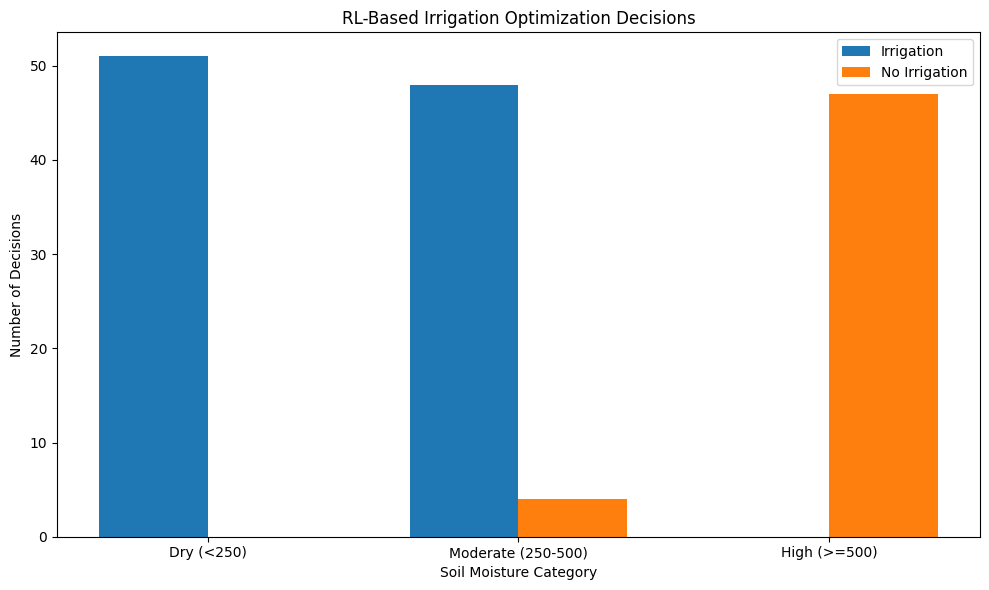

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import matplotlib.pyplot as plt

# Prepare visualization data
categories = ["Dry (<250)", "Moderate (250-500)", "High (>=500)"]

irrigation_counts = [
    summary.loc["Dry (<250)", "Irrigation"],
    summary.loc["Moderate (250-500)", "Irrigation"],
    summary.loc["High (>=500)", "Irrigation"]
]

no_irrigation_counts = [
    summary.loc["Dry (<250)", "No_Irrigation"],
    summary.loc["Moderate (250-500)", "No_Irrigation"],
    summary.loc["High (>=500)", "No_Irrigation"]
]

x = np.arange(len(categories))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    irrigation_counts,
    width,
    label="Irrigation"
)

plt.bar(
    x + width/2,
    no_irrigation_counts,
    width,
    label="No Irrigation"
)

plt.xlabel("Soil Moisture Category")
plt.ylabel("Number of Decisions")
plt.title("RL-Based Irrigation Optimization Decisions")
plt.xticks(x, categories)
plt.legend()

plt.tight_layout()
plt.show()